In [ ]:
# Shared bootstrap for notebooks organized by world.
from pathlib import Path
import os, sys
_here = Path.cwd().resolve()
_roots = ( _here, *_here.parents )
_root = next((p for p in _roots if (p / 'pyproject.toml').is_file() and (p / 'src').is_dir()), None)
if _root is None: raise FileNotFoundError('Launch Jupyter from inside the research repository')
if str(_root) not in sys.path: sys.path.insert(0, str(_root))
os.chdir(_root / 'notebooks')  # preserve paths from older notebooks
print('Repository root:', _root)

# Rehearsal-based staged training — paired multi-seed analysis

**Research question:** Does rehearsing earlier tasks during conjunction/binding training improve retention, end-to-end binding learning efficiency, and final performance **without changing model architecture or per-example exposure**?

Compare `mixed`, `staged`, `staged_rehearsal`, and `reverse`. Analyses use **fixed-final ID-development** metrics and paired seeds. The OOD-development split remains a secondary metric; test sets remain untouched.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent
RESULTS_PATH = ROOT / 'outputs/medium_world/experiments/rehearsal_five_seeds/schedule_comparison.json'
assert RESULTS_PATH.is_file(), f'Not found: {RESULTS_PATH}'
report = json.loads(RESULTS_PATH.read_text(encoding='utf-8'))
runs = report['runs']
TASKS = ['color', 'shape', 'conjunction', 'pair']
SCHEDULES = ['mixed', 'staged', 'staged_rehearsal', 'reverse']
print('Schedules:', report['config']['schedules'])
print('Seeds:', report['config']['seeds'])
print('LR policy:', report['config'].get('lr_policy'))
print('Number of completed runs:', len(runs))

Schedules: ['mixed', 'staged', 'staged_rehearsal', 'reverse']
Seeds: [42, 43, 44, 45, 46]
LR policy: mixed_reference
Number of completed runs: 20


## 1. Integrity: identical data, exposures, and realized LR

Check **exact total example presentations by task** and equal optimizer steps. The staged-rehearsal run also reports how replay is distributed by phase. LR should match at the same global update across schedules within each seed.


In [2]:
integrity = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'steps': r['steps_run'],
    'total_presentations': r['exposure_plan']['total_presentations'],
    **{f'{t}_presentations': r['exposure_plan']['counts_by_template'][t] for t in TASKS},
    'final_lr': r['final']['lr'], 'lr_changes': len(r['lr_reductions'])
} for r in runs]).sort_values(['seed','schedule']).reset_index(drop=True)
display(integrity)
assert len(runs)==len(report['config']['seeds'])*len(SCHEDULES)
assert set(integrity.schedule)==set(SCHEDULES)
assert all(integrity.steps==3000)
assert all(integrity.total_presentations==150000)
for task in TASKS: assert all(integrity[f'{task}_presentations']==37500)
for seed, subset in integrity.groupby('seed'):
    assert subset.final_lr.nunique()==1, f'Seed {seed}: final LR differed'

# Compare the LR applied after each common 100-step evaluation.
lr_rows = pd.DataFrame([{
    'seed':r['seed'], 'schedule':r['schedule'], 'step':h['step'],
    'lr_after':h['lr_after']}
    for r in runs for h in r['history'] if h['step']%100==0])
for (seed, step), subset in lr_rows.groupby(['seed','step']):
    assert subset.lr_after.nunique()==1, f'Unequal LR at seed={seed}, step={step}'
print('PASS: identical updates, task exposure counts, and LR trajectories.')
for r in runs:
    if r['schedule']=='staged_rehearsal' and r['seed']==min(report['config']['seeds']):
        display(pd.DataFrame(r['exposure_plan']['phase_task_presentations']).set_index('name'))

,seed,schedule,steps,total_presentations,color_presentations,shape_presentations,conjunction_presentations,pair_presentations,final_lr,lr_changes
0,42,mixed,3000,150000,37500,37500,37500,37500,0.0001,0
1,42,reverse,3000,150000,37500,37500,37500,37500,0.0001,0
2,42,staged,3000,150000,37500,37500,37500,37500,0.0001,0
3,42,staged_rehearsal,3000,150000,37500,37500,37500,37500,0.0001,0
4,43,mixed,3000,150000,37500,37500,37500,37500,0.0001,0
5,43,reverse,3000,150000,37500,37500,37500,37500,0.0001,0
6,43,staged,3000,150000,37500,37500,37500,37500,0.0001,0
7,43,staged_rehearsal,3000,150000,37500,37500,37500,37500,0.0001,0
8,44,mixed,3000,150000,37500,37500,37500,37500,0.0001,0
9,44,reverse,3000,150000,37500,37500,37500,37500,0.0001,0


PASS: identical updates, task exposure counts, and LR trajectories.


,by_template
name,
attributes,"{'color': 25000, 'shape': 25000}"
conjunction,"{'color': 2500, 'shape': 2500, 'conjunction': ..."
binding,"{'color': 2500, 'shape': 2500, 'conjunction': ..."
common_mixed,"{'color': 7500, 'shape': 7500, 'conjunction': ..."


## 2. Final accuracy and paired-seed summaries

All values except AULC are shown in **percent**. Report mean and sample standard deviation; do not select the best seed.


In [3]:
records=[]
for r in runs:
    f=r['final']
    records.append({
        'seed':r['seed'], 'schedule':r['schedule'],
        'overall_id':100*f['id_dev']['accuracy'],
        'ood_pair':100*f['ood_dev']['by_template']['pair'],
        'id_ce':f['id_dev']['loss'],
        'pair_aulc':100*r['id_pair_aulc'],
        **{t:100*f['id_dev']['by_template'][t] for t in TASKS}
    })
final=pd.DataFrame(records)
display(final.sort_values(['schedule','seed']).round(2))
display(final.groupby('schedule')[['overall_id','pair','pair_aulc','ood_pair',*TASKS[:3]]]
    .agg(['mean','std']).reindex(SCHEDULES).round(2))

,seed,schedule,overall_id,ood_pair,id_ce,pair_aulc,color,shape,conjunction,pair
0,42,mixed,74.41,54.75,0.45,53.32,98.83,63.28,80.08,55.47
4,43,mixed,73.24,53.00,0.46,53.40,99.61,62.11,80.08,51.17
8,44,mixed,72.56,57.00,0.48,51.63,98.05,60.55,80.08,51.56
12,45,mixed,73.63,52.50,0.46,54.29,98.44,60.16,78.91,57.03
16,46,mixed,68.36,54.50,0.55,52.34,89.06,60.55,71.48,52.34
3,42,reverse,71.48,55.50,0.47,53.05,97.66,58.59,76.17,53.52
7,43,reverse,73.63,52.50,0.46,51.15,98.83,63.67,80.08,51.95
11,44,reverse,72.17,54.25,0.47,50.49,98.83,58.98,78.91,51.95
15,45,reverse,71.09,52.50,0.52,51.30,94.92,57.42,74.61,57.42
19,46,reverse,65.92,52.00,0.57,51.56,85.16,58.98,66.41,53.12


overall_id         pair       pair_aulc       ood_pair        \
                       mean   std   mean   std      mean   std     mean   std   
schedule                                                                        
mixed                 72.44  2.38  53.52  2.59     53.00  1.03    54.35  1.76   
staged                73.20  1.37  55.86  3.63     52.70  0.86    53.30  5.53   
staged_rehearsal      73.59  1.46  55.47  3.24     53.08  0.97    54.15  2.45   
reverse               70.86  2.93  53.59  2.25     51.51  0.95    53.35  1.47   

                  color        shape       conjunction        
                   mean   std   mean   std        mean   std  
schedule                                                      
mixed             96.80  4.36  61.33  1.32       78.12  3.75  
staged            97.42  3.00  60.39  1.58       79.14  2.56  
staged_rehearsal  97.81  2.32  61.80  1.69       79.30  3.45  
reverse           95.08  5.77  59.53  2.40       75.23  5.39

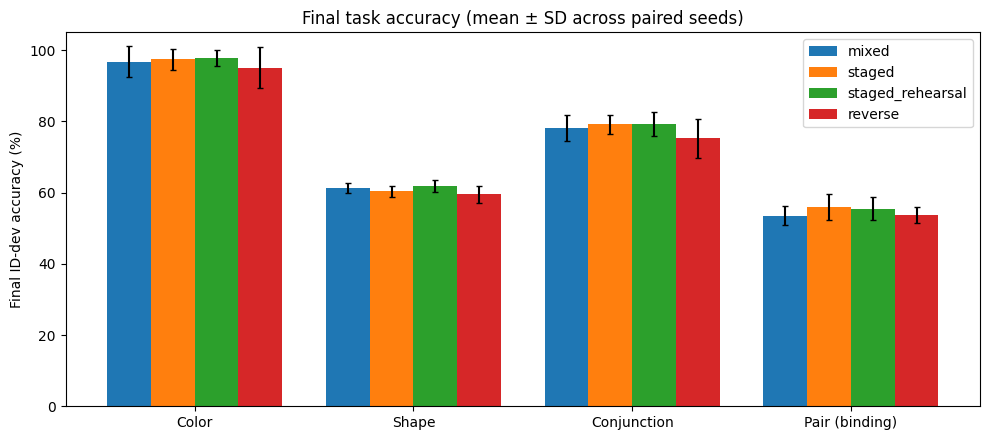

In [ ]:
means=final.groupby('schedule')[TASKS].mean().reindex(SCHEDULES)
stds=final.groupby('schedule')[TASKS].std().reindex(SCHEDULES)
fig,ax=plt.subplots(figsize=(10,4.5))
x=np.arange(len(TASKS))
width=.8/len(SCHEDULES)
for j,schedule in enumerate(SCHEDULES):
    off=(j-(len(SCHEDULES)-1)/2)*width
    ax.bar(x+off,means.loc[schedule].values,width,label=schedule,
           yerr=stds.loc[schedule].values,capsize=2)
ax.set_xticks(x,['Color','Shape','Conjunction','Pair (binding)'])
ax.set_ylabel('Final ID-dev accuracy (%)')
ax.set_ylim(0,105)
ax.set_title('Final task accuracy (mean ± SD across paired seeds)')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Learning curves and efficiency

Binding AULC averages performance across **all 3,000 updates**, including before the model first trains on binding. It is not a measure of speed *within* the binding-only stage.


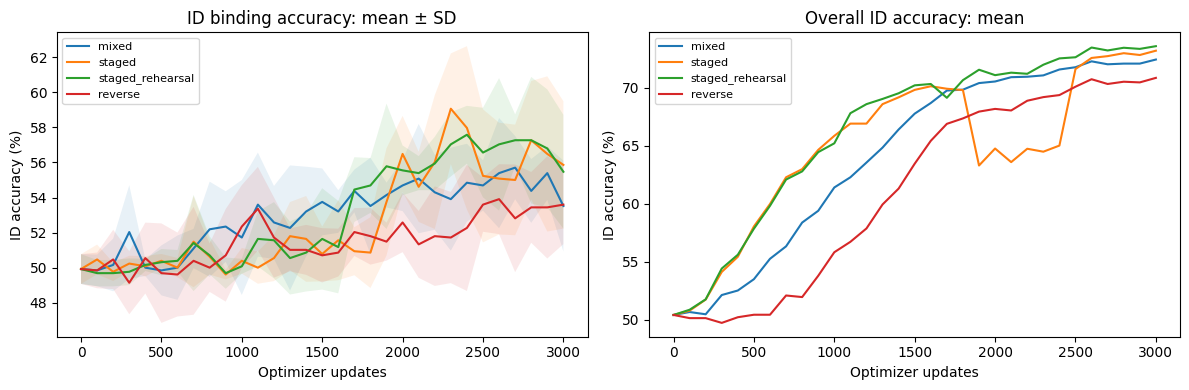

In [ ]:
history=pd.DataFrame([{
    'seed':r['seed'],'schedule':r['schedule'],'step':h['step'],
    'phase':h['phase'],'lr_after':h['lr_after'],
    'overall_id':100*h['id_dev']['accuracy'],
    'id_ce':h['id_dev']['loss'],
    **{t:100*h['id_dev']['by_template'][t] for t in TASKS}
} for r in runs for h in r['history']])
# Use only the shared 100-step grid, since rehearsal has extra phase boundaries.
grid=history[history.step%100==0].copy()
fig,axs=plt.subplots(1,2,figsize=(12,4))
for schedule in SCHEDULES:
    sub=grid[grid.schedule==schedule].groupby('step')['pair'].agg(['mean','std'])
    axs[0].plot(sub.index,sub['mean'],label=schedule)
    axs[0].fill_between(sub.index,(sub['mean']-sub['std']).to_numpy(),
                        (sub['mean']+sub['std']).to_numpy(),alpha=.10)
    sub=grid[grid.schedule==schedule].groupby('step')['overall_id'].mean()
    axs[1].plot(sub.index,sub.values,label=schedule)
axs[0].set_title('ID binding accuracy: mean ± SD')
axs[1].set_title('Overall ID accuracy: mean')
for ax in axs:
    ax.set(xlabel='Optimizer updates',ylabel='ID accuracy (%)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Paired differences (the main comparisons)

A positive difference means schedule A outperforms B. Percentile bootstrap intervals are descriptive only with five seeds. Results might change with more seeds; do not interpret intervals as definitive significance tests.


In [6]:
pairs=[('staged_rehearsal','staged'),('staged_rehearsal','mixed'),
       ('staged','mixed'),('staged','reverse')]
metrics=['pair','pair_aulc','overall_id','ood_pair','shape','conjunction']
rng=np.random.default_rng(2026)
results=[]
for a,b in pairs:
    for metric in metrics:
        pivot=final.pivot(index='seed',columns='schedule',values=metric)
        diff=(pivot[a]-pivot[b]).dropna().to_numpy()
        boot=rng.choice(diff,(10000,len(diff)),replace=True).mean(axis=1)
        lo,hi=np.percentile(boot,[2.5,97.5])
        results.append({'A':a,'B':b,'metric':metric,
                        'mean_diff_pp':diff.mean(), 'positive_seeds':int((diff>0).sum()),
                        'n_seeds':len(diff),'boot_low':lo,'boot_high':hi})
differences=pd.DataFrame(results)
display(differences.round(2))

,A,B,metric,mean_diff_pp,positive_seeds,n_seeds,boot_low,boot_high
0,staged_rehearsal,staged,pair,-0.39,1,5,-1.09,0.47
1,staged_rehearsal,staged,pair_aulc,0.38,5,5,0.09,0.66
2,staged_rehearsal,staged,overall_id,0.39,5,5,0.27,0.51
3,staged_rehearsal,staged,ood_pair,0.85,2,5,-1.65,3.75
4,staged_rehearsal,staged,shape,1.41,4,5,0.70,2.11
5,staged_rehearsal,staged,conjunction,0.16,4,5,-0.70,0.70
6,staged_rehearsal,mixed,pair,1.95,5,5,1.17,2.81
7,staged_rehearsal,mixed,pair_aulc,0.08,1,5,-0.32,0.71
8,staged_rehearsal,mixed,overall_id,1.15,4,5,0.20,2.13
9,staged_rehearsal,mixed,ood_pair,-0.20,1,5,-2.15,2.65


## 5. Does rehearsal reduce catastrophic forgetting?

For each actual phase transition, compare the last checkpoint in the previous phase with the first checkpoint in the next phase. These are short-term observations; subsequent consolidation may recover lost accuracy. Phase timings can differ between schedules.


In [7]:
changes=[]
for r in runs:
    if r['schedule'] not in ('staged','staged_rehearsal','reverse'):continue
    hist=sorted(r['history'],key=lambda h:h['step'])
    for before,after in zip(hist[:-1],hist[1:]):
        if before['phase'] in ('initial','common_mixed'):continue
        if before['phase']==after['phase']:continue
        changes.append({'seed':r['seed'],'schedule':r['schedule'],
            'transition':before['phase']+' -> '+after['phase'],
            'from_step':before['step'],'to_step':after['step'],
            **{f'delta_{t}':100*(after['id_dev']['by_template'][t]
                -before['id_dev']['by_template'][t]) for t in TASKS}})
transitions=pd.DataFrame(changes)
display(transitions.sort_values(['schedule','seed','from_step']).round(2))
display(transitions.groupby(['schedule','transition'])
        [[f'delta_{t}' for t in TASKS]].mean().round(2))

,seed,schedule,transition,from_step,to_step,delta_color,delta_shape,delta_conjunction,delta_pair
6,42,reverse,binding -> conjunction,600,700,3.12,0.00,5.47,1.95
7,42,reverse,conjunction -> attributes,1200,1300,7.03,7.03,0.78,-2.34
8,42,reverse,attributes -> common_mixed,2400,2500,0.78,1.17,0.39,-4.30
15,43,reverse,binding -> conjunction,600,700,6.64,-2.34,1.56,1.95
16,43,reverse,conjunction -> attributes,1200,1300,2.73,-1.17,0.39,0.00
17,43,reverse,attributes -> common_mixed,2400,2500,0.00,1.56,0.39,1.56
24,44,reverse,binding -> conjunction,600,700,0.78,0.00,4.69,3.52
25,44,reverse,conjunction -> attributes,1200,1300,6.25,2.73,1.17,1.17
26,44,reverse,attributes -> common_mixed,2400,2500,0.00,0.00,2.34,7.42
33,45,reverse,binding -> conjunction,600,700,0.00,0.00,0.00,-1.56


delta_color  delta_shape  \
schedule         transition                                             
reverse          attributes -> common_mixed         0.39         0.78   
                 binding -> conjunction             3.52        -0.47   
                 conjunction -> attributes          4.53         3.20   
staged           attributes -> conjunction         -1.88        -0.39   
                 binding -> common_mixed           13.12         4.45   
                 conjunction -> binding           -12.97        -2.89   
staged_rehearsal attributes -> conjunction          1.02         0.62   
                 binding -> common_mixed            1.25        -1.41   
                 conjunction -> binding            -1.17        -2.27   

                                             delta_conjunction  delta_pair  
schedule         transition                                                 
reverse          attributes -> common_mixed               0.39        1.33  
                 binding -> conjunction                   2.81        0.78  
                 conjunction -> attributes                1.25       -0.70  
staged           attributes -> conjunction                7.73        1.25  
                 binding -> common_mixed                 11.56       -2.73  
                 conjunction -> binding                 -13.05        2.89  
staged_rehearsal attributes -> conjunction                7.19        1.56  
                 binding -> common_mixed                  1.56       -1.02  
                 conjunction -> binding                  -6.72        3.75

## 6. Interpretation guide

Answer these with *paired evidence*:

1. Does `staged_rehearsal` preserve color/shape/conjunction performance better at stage switches than `staged`?
2. Does that retention translate into higher **final pair accuracy** or better **pair AULC**?
3. Does a binding gain also hold on OOD-development pairs, or only on ID-development?
4. Are results consistent across seeds, and what uncertainty remains?
5. Does any apparent gain occur because pair training begins at a different step? Treat stage allocation as part of the intervention, not a pure memory-replay causal effect.

Keep the architecture frozen. The next design decision should follow these results—not a best-seed anecdote. Do not evaluate held-out test splits while developing the curriculum.
